# 03 · Supervisé : Random Forest vs MLP, explications SHAP

**Date :** 3 novembre 2026

**Ce qui est fait :**
1. Random Forest multi-classe (benign + 7 attaques connues) : petite grille de réglages, choisie sur val (macro-F1).
2. MLP (sklearn) : 3 tailles de réseau, entraînées époque par époque, meilleure époque choisie sur val.
3. Comparaison RF vs MLP : métriques **par classe** sur val (attaques connues).
4. Sur test (jeu + ven, attaques **jamais vues**) : part de chaque attaque signalée comme « attaque » (quelle que soit l'étiquette donnée) et fausses alertes sur le benign.
5. SHAP (TreeExplainer) sur le RF : caractéristiques les plus utilisées, puis explication d'une alerte.

**Pourquoi :** c'est la première comparaison demandée (RF vs MLP). Le RF retenu fournira l'étiquette « attaque connue » et ses explications SHAP aux agents (notebooks 05 et 07).

Rien n'est réglé sur test (règle 7) : le test sert seulement à mesurer.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, str(Path.cwd().parent / "src"))
from isocrates.ml.data import LABEL, BENIGN, ROOT
from isocrates.ml.supervised import (load_sets, signed_log, fit_rf, fit_mlp, macro_f1,
                                     per_class_report, detection_by_class, save_model)

REPORTS = ROOT / "reports"
sns.set_theme(style="whitegrid")

sets, features = load_sets()

# X = caractéristiques (tableau numpy), y = étiquettes
X_train = sets["train"][features].to_numpy(np.float32)
X_val = sets["val"][features].to_numpy(np.float32)
X_test = sets["test"][features].to_numpy(np.float32)
y_train = sets["train"][LABEL].to_numpy()
y_val = sets["val"][LABEL].to_numpy()
y_test = sets["test"][LABEL].to_numpy()

known = sorted(set(y_train))   # les 8 classes connues du modèle
print(len(features), "caractéristiques")
print("Classes connues :", known)
print("Flux : train", len(y_train), "· val", len(y_val), "· test", len(y_test))

78 caractéristiques
Classes connues : ['benign', 'dos_goldeneye', 'dos_hulk', 'dos_slowhttptest', 'dos_slowloris', 'ftp_patator', 'heartbleed', 'ssh_patator']
Flux : train 945640 · val 236415 · test 655443


## 1. Random Forest : réglage sur val

100 arbres. On essaie 6 combinaisons : profondeur maximale (10, 20, illimitée) × poids de classe (aucun, `balanced_subsample`). Critère : **macro-F1** sur val (moyenne des F1 des 8 classes, chacune compte autant).

In [2]:
rf_results = []
rf_models = []

for depth in [10, 20, None]:
    for weight in [None, "balanced_subsample"]:
        model, duration = fit_rf(X_train, y_train, max_depth=depth, class_weight=weight)
        score = macro_f1(y_val, model.predict(X_val))
        rf_results.append({
            "max_depth": "illimitée" if depth is None else depth,
            "class_weight": "aucun" if weight is None else weight,
            "macro-F1 val": round(score, 4),
            "temps (s)": round(duration),
        })
        rf_models.append(model)

rf_table = pd.DataFrame(rf_results)
best = rf_table["macro-F1 val"].idxmax()   # numéro de la meilleure ligne
rf = rf_models[best]
print("Retenu :", rf_table.loc[best].to_dict())
rf_table

Retenu : {'max_depth': 10, 'class_weight': 'aucun', 'macro-F1 val': 0.9681, 'temps (s)': 25}


,max_depth,class_weight,macro-F1 val,temps (s)
0,10,aucun,0.9681,25
1,10,balanced_subsample,0.9393,30
2,20,aucun,0.9388,28
3,20,balanced_subsample,0.9366,31
4,illimitée,aucun,0.9389,29
5,illimitée,balanced_subsample,0.9357,32


## 2. MLP : réglage sur val

Un réseau de neurones a besoin d'entrées à la même échelle :
1. `sign(x)·log(1+|x|)` écrase les très grandes valeurs (débits, durées en µs) ;
2. `StandardScaler` (moyenne 0, écart-type 1), **ajusté sur train seulement**.

3 tailles de couches cachées, 20 époques chacune (lots de 1 024 flux, Adam). Poids des classes en racine de « balanced ». À chaque époque on calcule le macro-F1 sur **notre** val temporelle et on garde la meilleure époque.

In [3]:
scaler = StandardScaler()
scaler.fit(signed_log(X_train))          # moyenne et écart-type calculés sur train uniquement
Z_train = scaler.transform(signed_log(X_train))
Z_val = scaler.transform(signed_log(X_val))
Z_test = scaler.transform(signed_log(X_test))

mlp_results = []
mlp_models = []
histories = {}

for hidden in [(64, 32), (128, 64), (256, 128)]:
    model, history, best_epoch, duration = fit_mlp(Z_train, y_train, Z_val, y_val, hidden=hidden, epochs=20)
    histories[str(hidden)] = history
    mlp_results.append({
        "couches": str(hidden),
        "meilleure époque": best_epoch,
        "macro-F1 val": round(history["macro-F1 val"].max(), 4),
        "temps (s)": round(duration),
    })
    mlp_models.append(model)

mlp_table = pd.DataFrame(mlp_results)
best = mlp_table["macro-F1 val"].idxmax()
mlp = mlp_models[best]
print("Retenu :", mlp_table.loc[best].to_dict())
mlp_table

Retenu : {'couches': '(128, 64)', 'meilleure époque': 16, 'macro-F1 val': 0.9637, 'temps (s)': 111}


,couches,meilleure époque,macro-F1 val,temps (s)
0,"(64, 32)",18,0.9626,121
1,"(128, 64)",16,0.9637,111
2,"(256, 128)",19,0.9551,264


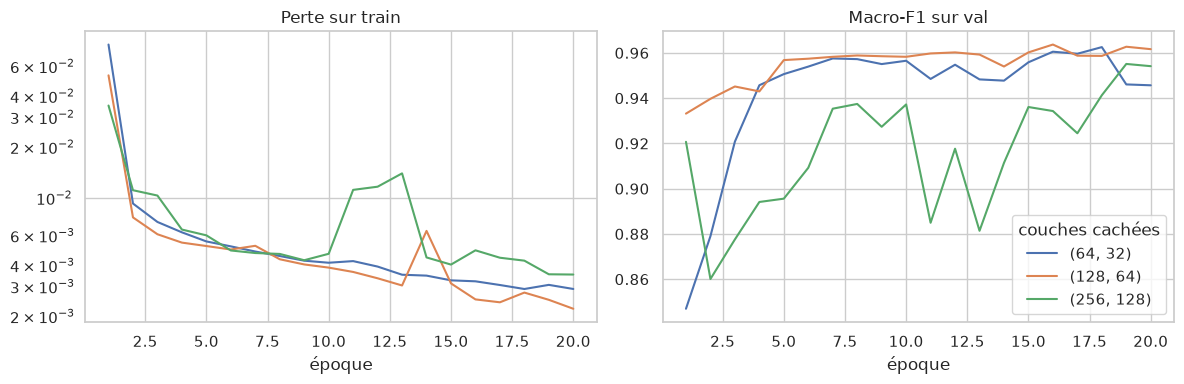

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in histories.items():
    axes[0].plot(history["époque"], history["perte train"], label=name)
    axes[1].plot(history["époque"], history["macro-F1 val"], label=name)
axes[0].set_title("Perte sur train")
axes[0].set_xlabel("époque")
axes[0].set_yscale("log")
axes[1].set_title("Macro-F1 sur val")
axes[1].set_xlabel("époque")
axes[1].legend(title="couches cachées")
fig.tight_layout()
fig.savefig(REPORTS / "03_mlp_epoques.png", dpi=150)
plt.show()

## 3. Comparaison sur val (attaques connues)

In [5]:
rf_val = rf.predict(X_val)
mlp_val = mlp.predict(Z_val)
rf_test = rf.predict(X_test)
mlp_test = mlp.predict(Z_test)

rf_report = per_class_report(y_val, rf_val, known)
mlp_report = per_class_report(y_val, mlp_val, known)
pd.concat({"RF": rf_report, "MLP": mlp_report}, axis=1)

RF                             MLP                \
                 précision rappel     F1    flux précision rappel     F1   
benign               1.000  1.000  1.000  199759     1.000  1.000  1.000   
dos_goldeneye        1.000  0.994  0.997    1353     0.999  0.993  0.996   
dos_hulk             1.000  1.000  1.000   31798     1.000  1.000  1.000   
dos_slowhttptest     0.815  0.996  0.896     974     0.772  0.996  0.870   
dos_slowloris        0.997  0.795  0.884    1135     0.993  0.760  0.861   
ftp_patator          1.000  1.000  1.000     801     1.000  1.000  1.000   
heartbleed           1.000  1.000  1.000       3     1.000  1.000  1.000   
ssh_patator          1.000  0.936  0.967     592     1.000  0.966  0.983   

                          
                    flux  
benign            199759  
dos_goldeneye       1353  
dos_hulk           31798  
dos_slowhttptest     974  
dos_slowloris       1135  
ftp_patator          801  
heartbleed             3  
ssh_patator          592

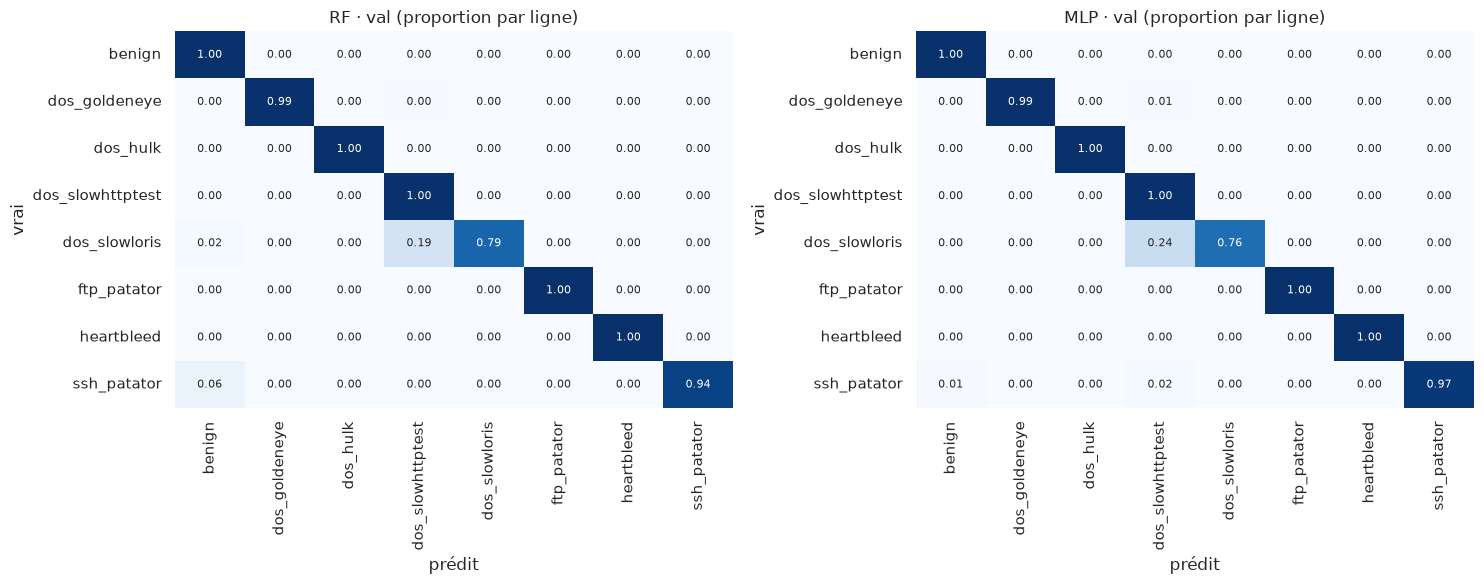

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, name, predictions in [(axes[0], "RF", rf_val), (axes[1], "MLP", mlp_val)]:
    # matrice de confusion en proportion de chaque ligne (chaque vraie classe)
    cm = pd.crosstab(pd.Series(y_val, name="vrai"), pd.Series(predictions, name="prédit"), normalize="index")
    cm = cm.reindex(index=known, columns=known, fill_value=0)
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax, annot_kws={"size": 8})
    ax.set_title(name + " · val (proportion par ligne)")
fig.tight_layout()
fig.savefig(REPORTS / "03_confusion_val.png", dpi=150)
plt.show()

## 4. Test : attaques jamais vues

Le RF et le MLP ne connaissent aucune de ces attaques par leur nom. On mesure donc la **détection** : part des flux de chaque classe prédits comme n'importe quelle attaque (≠ benign). Pour benign, c'est le taux de fausses alertes.

In [7]:
detection = pd.DataFrame({
    "RF": detection_by_class(y_test, rf_test),
    "MLP": detection_by_class(y_test, mlp_test),
})
detection["flux"] = pd.Series(y_test).value_counts()
detection.round(3)

,RF,MLP,flux
benign,0.000,0.000,396886
bot,0.000,0.000,735
ddos,0.986,1.000,95683
portscan,0.000,0.000,160106
webattack_bruteforce,0.000,0.940,1360
webattack_sql_injection,0.000,0.167,12
webattack_xss,0.002,0.997,661


In [8]:
# Sous quelle étiquette connue le RF range-t-il chaque attaque inconnue ? (proportion par ligne)
table = pd.crosstab(pd.Series(y_test, name="vrai (test)"), pd.Series(rf_test, name="prédit par le RF"),
                    normalize="index").round(3)
table

prédit par le RF,benign,dos_goldeneye,dos_hulk
vrai (test),,,
benign,1.000,0.000,0.000
bot,1.000,0.000,0.000
ddos,0.014,0.000,0.986
portscan,1.000,0.000,0.000
webattack_bruteforce,1.000,0.000,0.000
webattack_sql_injection,1.000,0.000,0.000
webattack_xss,0.998,0.002,0.000


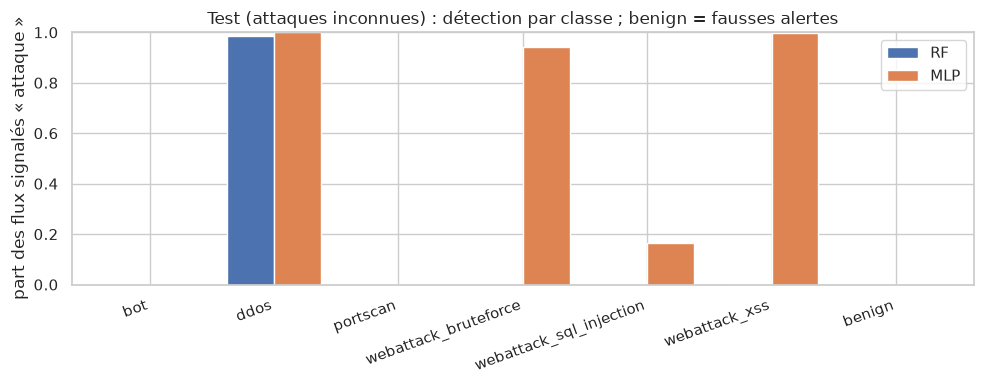

In [9]:
test_attacks = [name for name in detection.index if name != BENIGN]

fig, ax = plt.subplots(figsize=(10, 4))
detection.loc[test_attacks + [BENIGN], ["RF", "MLP"]].plot.bar(ax=ax, width=0.75, color=["#4C72B0", "#DD8452"])
ax.set_ylabel("part des flux signalés « attaque »")
ax.set_ylim(0, 1)
ax.set_title("Test (attaques inconnues) : détection par classe ; benign = fausses alertes")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
fig.tight_layout()
fig.savefig(REPORTS / "03_detection_test.png", dpi=150)
plt.show()

In [10]:
# Temps de prédiction pour 100 000 flux
start = time.perf_counter()
rf.predict(X_test[:100_000])
rf_time = time.perf_counter() - start

start = time.perf_counter()
mlp.predict(scaler.transform(signed_log(X_test[:100_000])))
mlp_time = time.perf_counter() - start

summary = pd.DataFrame({
    "macro-F1 val": [rf_table["macro-F1 val"].max(), mlp_table["macro-F1 val"].max()],
    "prédiction 100 000 flux (s)": [round(rf_time, 2), round(mlp_time, 2)],
    "fausses alertes test (benign)": [detection.loc[BENIGN, "RF"], detection.loc[BENIGN, "MLP"]],
}, index=["RF", "MLP"])
summary

,macro-F1 val,prédiction 100 000 flux (s),fausses alertes test (benign)
RF,0.9681,0.22,0.000003
MLP,0.9637,0.31,0.000116


## 5. SHAP : pourquoi le RF décide

TreeExplainer calcule, pour chaque flux, la **contribution** de chaque caractéristique au score de chaque classe : une valeur positive pousse vers la classe, une valeur négative éloigne.

Échantillon de val : au plus 100 flux par classe (graine fixe).

In [11]:
# Échantillon : au plus 100 flux de val par classe
rng = np.random.default_rng(0)
sample_index = []
for name in known:
    positions = np.flatnonzero(y_val == name)          # numéros des flux de cette classe
    n = min(len(positions), 100)
    sample_index.extend(rng.choice(positions, size=n, replace=False))
sample_index = np.array(sample_index)
X_sample = X_val[sample_index]
y_sample = y_val[sample_index]
print("Flux par classe dans l'échantillon :", pd.Series(y_sample).value_counts().to_dict())

explainer = shap.TreeExplainer(rf)
start = time.perf_counter()
shap_values = explainer(X_sample)
shap_values.feature_names = features
print("SHAP calculé en", round(time.perf_counter() - start), "s ; forme", shap_values.values.shape, "= (flux, caractéristiques, classes)")

Flux par classe dans l'échantillon : {'benign': 100, 'dos_goldeneye': 100, 'dos_hulk': 100, 'dos_slowhttptest': 100, 'dos_slowloris': 100, 'ftp_patator': 100, 'ssh_patator': 100, 'heartbleed': 3}


SHAP calculé en 3 s ; forme (703, 78, 8) = (flux, caractéristiques, classes)


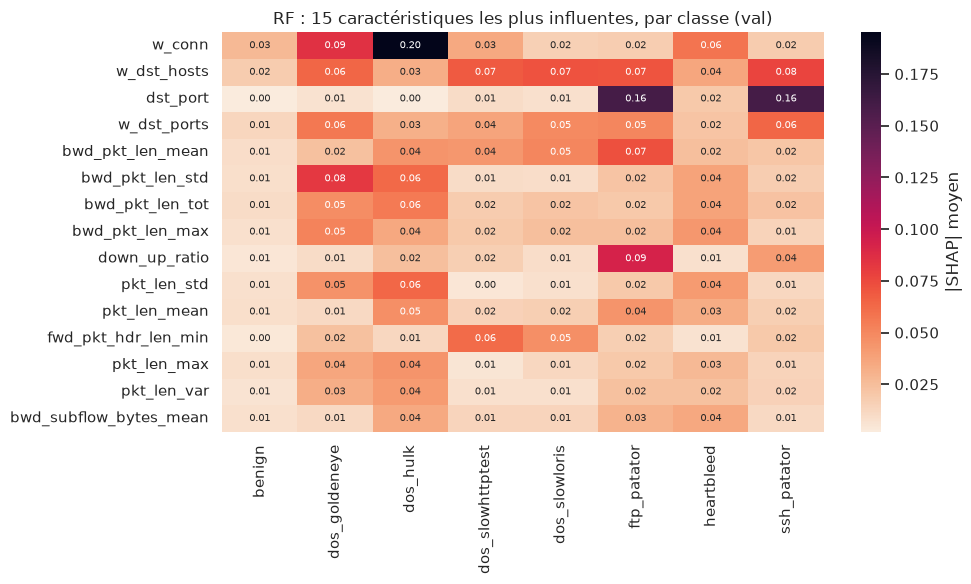

In [12]:
# Importance de chaque caractéristique pour chaque classe :
# moyenne de |SHAP| sur les flux de cette classe, pour le score de cette classe
classes = list(rf.classes_)
importance = pd.DataFrame(index=features)
for k, name in enumerate(classes):
    rows = y_sample == name
    importance[name] = np.abs(shap_values.values[rows, :, k]).mean(axis=0)

top15 = importance.sum(axis=1).sort_values(ascending=False).head(15).index

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(importance.loc[top15], cmap="rocket_r", annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax,
            cbar_kws={"label": "|SHAP| moyen"})
ax.set_title("RF : 15 caractéristiques les plus influentes, par classe (val)")
fig.tight_layout()
fig.savefig(REPORTS / "03_shap_global.png", dpi=150)
plt.show()

### Explication d'une alerte

Un des rares flux de **portscan** du test (attaque inconnue du RF) qu'il signale comme attaque : quelle étiquette connue lui donne-t-il, et pourquoi ? C'est ce type d'explication que recevront les agents.

In [13]:
flagged = np.flatnonzero((y_test == "portscan") & (rf_test != BENIGN))
print(len(flagged), "flux de portscan sur", (y_test == "portscan").sum(), "sont signalés par le RF")

i = rng.choice(flagged)                       # on en choisit un au hasard (graine fixe)
predicted = rf_test[i]
k = classes.index(predicted)
probability = rf.predict_proba(X_test[[i]])[0, k]
print("Flux test n°", i, ": vrai = portscan, prédit =", predicted, "avec une probabilité de", round(probability, 2))

one = explainer(X_test[[i]])
one.feature_names = features

# Les 8 caractéristiques qui ont le plus pesé
contributions = pd.DataFrame({"valeur": X_test[i], "SHAP": one.values[0, :, k]}, index=features)
contributions["|SHAP|"] = contributions["SHAP"].abs()
contributions.sort_values("|SHAP|", ascending=False).head(8).drop(columns="|SHAP|").round(3)

35 flux de portscan sur 160106 sont signalés par le RF
Flux test n° 504700 : vrai = portscan, prédit = dos_goldeneye avec une probabilité de 0.45


,valeur,SHAP
bwd_pkt_len_std,2.181008e+03,0.070
w_conn,4.036000e+03,0.062
bwd_iat_tot,6.007607e+06,0.041
pkt_len_std,1.975064e+03,0.037
pkt_len_max,5.792000e+03,0.037
w_dst_hosts,1.000000e+00,0.034
bwd_pkt_len_max,5.792000e+03,0.034
w_dst_ports,9.990000e+02,-0.031


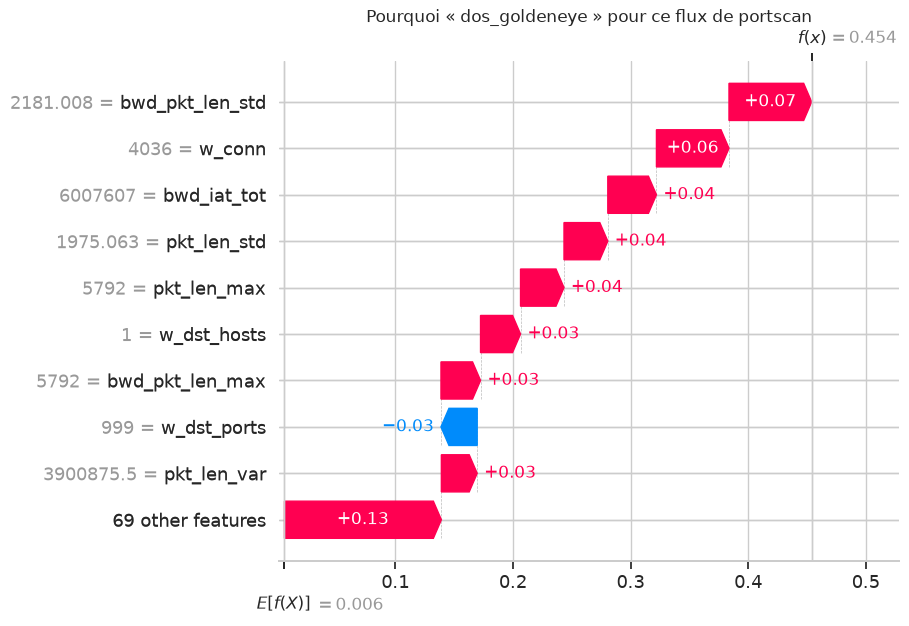

In [14]:
shap.plots.waterfall(one[0, :, k], max_display=10, show=False)
plt.title("Pourquoi « " + predicted + " » pour ce flux de portscan")
plt.gcf().savefig(REPORTS / "03_shap_exemple.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Sauvegarde des modèles

Dans `models/` (exclu de Git) : le RF retenu, et le MLP retenu avec son scaler (il faut le même scaler pour prédire).

In [15]:
save_model(rf, "rf")
save_model({"scaler": scaler, "mlp": mlp}, "mlp")
for path in sorted((ROOT / "models").glob("*.joblib")):
    print(path.name, ":", round(path.stat().st_size / 1e6, 1), "Mo")

mlp.joblib : 0.3 Mo
rf.joblib : 0.8 Mo


## Observations

_À compléter après exécution._